# Finance personnelle et machine learning

Dataset : `synthetic_personal_finance_dataset.csv` (32 424 personnes, 20 colonnes, relevés de juillet 2021 à juillet 2025).

## 1. Contexte

Le dataset est présenté comme utilisable pour plusieurs choses : éligibilité à un prêt, prédiction du score de crédit, analyse des dépenses / épargne, segmentation selon le ratio dette/revenu (DTI), dashboards. J'ai essayé de traiter chacun de ces points :

| Objectif | Partie |
|---|---|
| Éligibilité au prêt | 7.2 et 8 |
| Score de crédit | 7.1 |
| Dépenses et épargne | 9 |
| Segmentation DTI | 10 |
| Dashboard | 11 |

Comme les données sont synthétiques, je commence par regarder quelles relations existent vraiment entre les variables avant de lancer des modèles. Pour la partie modélisation :
- split train/test temporel (on entraîne sur le passé, on teste sur la dernière année),
- pas de variables connues seulement après l'octroi du prêt (montant, mensualité, taux),
- toujours comparer à une baseline simple.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import permutation_test_score, StratifiedKFold
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression, Ridge
from sklearn.ensemble import HistGradientBoostingRegressor, HistGradientBoostingClassifier
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.metrics import (mean_absolute_error, r2_score, roc_auc_score,
                             roc_curve, silhouette_score)
from sklearn.cluster import KMeans
from scipy import stats

RANDOM_STATE = 42
DATA_PATH = "data/synthetic_personal_finance_dataset.csv"

# couleurs et style des graphiques
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
sns.set_theme(style="whitegrid", palette=PALETTE)
plt.rcParams.update({
    "figure.dpi": 80, "savefig.dpi": 80, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "grid.color": "#e6e5e0", "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "axes.spines.top": False, "axes.spines.right": False, "lines.linewidth": 2,
})
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

## 2. Chargement des données

In [2]:
df_raw = pd.read_csv(DATA_PATH, parse_dates=["record_date"])
print(df_raw.shape)
df_raw.head()

(32424, 20)


,user_id,age,gender,education_level,employment_status,job_title,monthly_income_usd,monthly_expenses_usd,savings_usd,has_loan,loan_type,loan_amount_usd,loan_term_months,monthly_emi_usd,loan_interest_rate_pct,debt_to_income_ratio,credit_score,savings_to_income_ratio,region,record_date
0,U00001,56,Female,High School,Self-employed,Salesperson,"3,531.690","1,182.590","367,655.030",No,NaN,0.000,0,0.000,0.000,0.000,430,8.680,Other,2024-01-09
1,U00002,19,Female,PhD,Employed,Salesperson,"3,531.730","2,367.990","260,869.100",Yes,Education,"146,323.340",36,"4,953.500",13.330,1.400,543,6.160,North America,2022-02-13
2,U00003,20,Female,Master,Employed,Teacher,"2,799.490","1,003.910","230,921.210",No,NaN,0.000,0,0.000,0.000,0.000,754,6.870,Africa,2022-05-12
3,U00004,25,Male,PhD,Employed,Manager,"5,894.880","4,440.120","304,815.510",Yes,Business,"93,242.370",24,"4,926.570",23.930,0.840,461,4.310,Europe,2023-10-02
4,U00005,53,Female,PhD,Employed,Student,"5,128.930","4,137.610","461,509.480",No,NaN,0.000,0,0.000,0.000,0.000,516,7.500,Africa,2021-08-07


In [3]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 32424 entries, 0 to 32423
Data columns (total 20 columns):
 #   Column                   Non-Null Count  Dtype         
---  ------                   --------------  -----         
 0   user_id                  32424 non-null  str           
 1   age                      32424 non-null  int64         
 2   gender                   32424 non-null  str           
 3   education_level          32424 non-null  str           
 4   employment_status        32424 non-null  str           
 5   job_title                32424 non-null  str           
 6   monthly_income_usd       32424 non-null  float64       
 7   monthly_expenses_usd     32424 non-null  float64       
 8   savings_usd              32424 non-null  float64       
 9   has_loan                 32424 non-null  str           
 10  loan_type                12995 non-null  str           
 11  loan_amount_usd          32424 non-null  float64       
 12  loan_term_months         32424 non-null  in

## 3. Qualité des données

Vérifications de base : valeurs manquantes, doublons, types, et cohérence entre colonnes (par exemple un non-emprunteur doit avoir un montant de prêt à 0).

In [4]:
print("Doublons user_id :", df_raw.user_id.duplicated().sum())
print("Lignes dupliquées :", df_raw.duplicated().sum())
print("\nManquants par colonne :")
print(df_raw.isna().sum()[lambda s: s > 0])
print("\nValeurs de has_loan :", df_raw.has_loan.unique())

Doublons user_id : 0
Lignes dupliquées : 0

Manquants par colonne :
loan_type    19429
dtype: int64

Valeurs de has_loan : <StringArray>
['No', 'Yes']
Length: 2, dtype: str


Les 19 429 valeurs manquantes de `loan_type` sont exactement les personnes sans prêt : pandas a lu la chaîne `"None"` comme `NaN`. Je la remplace par `"No loan"`.

In [5]:
df = df_raw.copy()
df["has_loan"] = df["has_loan"].map({"Yes": 1, "No": 0}).astype(int)
df["loan_type"] = df["loan_type"].fillna("No loan")

# les non-emprunteurs ont bien des champs de prêt à 0 ?
loan_cols = ["loan_amount_usd", "loan_term_months", "monthly_emi_usd", "loan_interest_rate_pct", "debt_to_income_ratio"]
no_loan = df[df.has_loan == 0]
print("Non-emprunteurs avec un champ de prêt ≠ 0 :", (no_loan[loan_cols] != 0).any(axis=1).sum())
print("Non-emprunteurs avec loan_type ≠ 'No loan' :", (no_loan.loan_type != "No loan").sum())
print("Emprunteurs avec montant nul :", ((df.has_loan == 1) & (df.loan_amount_usd == 0)).sum())
print("Dépenses > revenus :", (df.monthly_expenses_usd > df.monthly_income_usd).sum())

Non-emprunteurs avec un champ de prêt ≠ 0 : 0
Non-emprunteurs avec loan_type ≠ 'No loan' : 0
Emprunteurs avec montant nul : 0
Dépenses > revenus : 0


### 3.1 Colonnes calculées

Certaines colonnes ont l'air d'être calculées à partir d'autres. Je vérifie, parce que si c'est le cas un modèle ne fera que retrouver la formule.

In [6]:
b = df[df.has_loan == 1]
r, n, P = b.loan_interest_rate_pct / 1200, b.loan_term_months, b.loan_amount_usd
emi_formula = P * r * (1 + r) ** n / ((1 + r) ** n - 1)          # formule d'annuité constante

checks = pd.DataFrame({
    "relation testée": [
        "monthly_emi = annuité(montant, taux, durée)",
        "debt_to_income = emi / revenu mensuel",
        "savings_to_income = épargne / (12 × revenu mensuel)",
        "dépenses / revenu ∈ [0.30 ; 0.90]",
    ],
    "écart max": [
        (emi_formula / b.monthly_emi_usd - 1).abs().max(),
        (b.monthly_emi_usd / b.monthly_income_usd - b.debt_to_income_ratio).abs().max(),
        (df.savings_usd / (12 * df.monthly_income_usd) - df.savings_to_income_ratio).abs().max(),
        np.nan,
    ],
})
ratio = df.monthly_expenses_usd / df.monthly_income_usd
checks.loc[3, "écart max"] = 0.0 if ratio.between(0.3, 0.9).all() else 1.0
checks

,relation testée,écart max
0,"monthly_emi = annuité(montant, taux, durée)",0.000
1,debt_to_income = emi / revenu mensuel,0.005
2,savings_to_income = épargne / (12 × revenu men...,0.005
3,dépenses / revenu ∈ [0.30 ; 0.90],0.000


À l'arrondi près, `monthly_emi_usd` suit la formule classique d'un prêt à mensualités constantes, `debt_to_income_ratio` = mensualité / revenu mensuel et `savings_to_income_ratio` = épargne / revenu annuel. Les dépenses représentent toujours entre 30 % et 90 % du revenu.

Attention : ici le DTI est mensualité / revenu mensuel. Un DTI de 1,4 veut dire que la mensualité fait 140 % du revenu, ce qui n'arriverait pas dans la réalité.

In [7]:
# job_title vs employment_status
pd.crosstab(df.job_title, df.employment_status)

employment_status,Employed,Self-employed,Student,Unemployed
job_title,,,,
Accountant,2144,721,372,354
Doctor,2131,720,355,348
Driver,2264,719,362,353
Engineer,2098,728,341,337
Manager,2168,698,358,397
Salesperson,2138,746,325,358
Student,2136,743,350,380
Teacher,2155,777,397,345
Unemployed,2176,728,354,348


`job_title` n'a pas de lien avec `employment_status` (il y a des « Doctor » étudiants, des « Unemployed » salariés...). Je garde `employment_status` et je laisse `job_title` de côté pour les modèles.

## 4. Analyse exploratoire

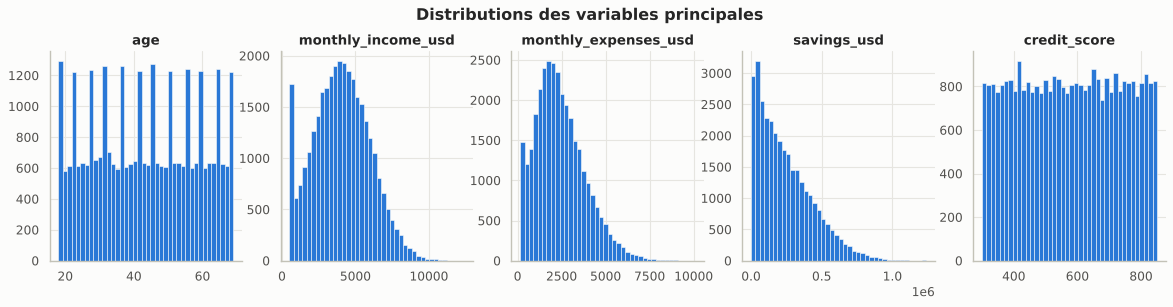

In [8]:
num_cols = ["age", "monthly_income_usd", "monthly_expenses_usd", "savings_usd", "credit_score"]
fig, axes = plt.subplots(1, 5, figsize=(18, 3.4))
for ax, c in zip(axes, num_cols):
    ax.hist(df[c], bins=40, color=PALETTE[0], edgecolor="#fcfcfb", linewidth=0.5)
    ax.set_title(c); ax.set_ylabel("")
fig.suptitle("Distributions des variables principales", y=1.04, fontweight="bold")
plt.show()

- L'âge et le score de crédit sont distribués de façon uniforme (18-69 ans, 300-850). Dans des vraies données le score serait plutôt concentré autour de 650-750.
- Le revenu est en cloche, moyenne autour de 4 000 $/mois, minimum 500 $.
- L'épargne va jusqu'à 1,2 M$, ce qui colle avec un ratio épargne/revenu annuel entre 0,1 et 10.

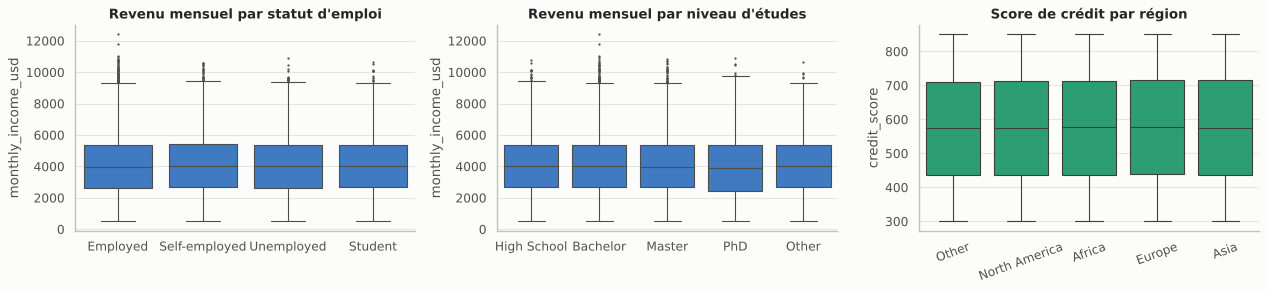

                   monthly_income_usd  credit_score
employment_status                                  
Employed                    4,018.000       575.300
Self-employed               4,048.000       573.300
Student                     4,052.300       574.000
Unemployed                  4,021.600       580.500
education_level
Bachelor      4,031.000
High School   4,040.000
Master        4,019.000
Other         4,049.000
PhD           3,991.000
Name: monthly_income_usd, dtype: float64


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
order = df.employment_status.value_counts().index
sns.boxplot(data=df, x="employment_status", y="monthly_income_usd", order=order, ax=axes[0], color=PALETTE[0], fliersize=1)
axes[0].set_title("Revenu mensuel par statut d'emploi"); axes[0].set_xlabel("")
sns.boxplot(data=df, x="education_level", y="monthly_income_usd",
            order=["High School", "Bachelor", "Master", "PhD", "Other"], ax=axes[1], color=PALETTE[0], fliersize=1)
axes[1].set_title("Revenu mensuel par niveau d'études"); axes[1].set_xlabel("")
sns.boxplot(data=df, x="region", y="credit_score", ax=axes[2], color=PALETTE[2], fliersize=1)
axes[2].set_title("Score de crédit par région"); axes[2].set_xlabel(""); axes[2].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

print(df.groupby("employment_status")[["monthly_income_usd", "credit_score"]].mean().round(1))
print(df.groupby("education_level")["monthly_income_usd"].mean().round(0))

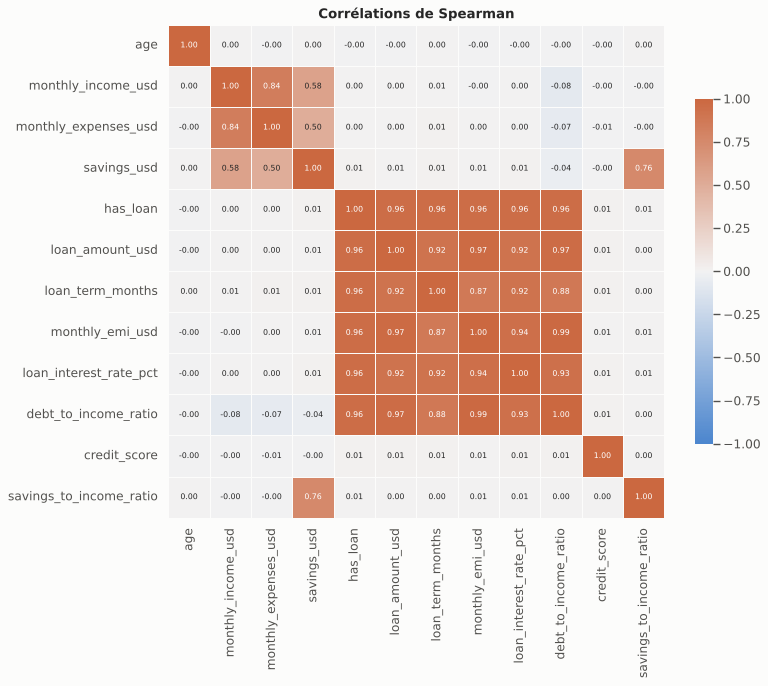

In [10]:
corr_cols = ["age", "monthly_income_usd", "monthly_expenses_usd", "savings_usd", "has_loan", "loan_amount_usd",
             "loan_term_months", "monthly_emi_usd", "loan_interest_rate_pct", "debt_to_income_ratio",
             "credit_score", "savings_to_income_ratio"]
corr = df[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap=sns.diverging_palette(250, 25, s=75, l=55, as_cmap=True), center=0, vmin=-1, vmax=1,
            annot=True, fmt=".2f", annot_kws={"size": 7}, linewidths=0.5, linecolor="#fcfcfb", ax=ax,
            cbar_kws={"shrink": 0.7})
ax.set_title("Corrélations de Spearman")
plt.show()

Sur la heatmap, la ligne `credit_score` est à 0 partout, et `has_loan` aussi (sauf avec les colonnes de prêt, qui en dépendent directement). Les seules corrélations fortes viennent des colonnes calculées : revenu / dépenses / épargne d'un côté, montant / mensualité / DTI de l'autre.

Je le vérifie avec des tests statistiques.

In [11]:
rows = []
for c in ["age", "monthly_income_usd", "monthly_expenses_usd", "savings_usd", "savings_to_income_ratio"]:
    rho, p = stats.spearmanr(df[c], df.credit_score)
    rows.append(("credit_score", c, "Spearman", rho, p))
    rho, p = stats.spearmanr(df[c], df.has_loan)
    rows.append(("has_loan", c, "Spearman", rho, p))
for c in ["gender", "education_level", "employment_status", "region", "job_title"]:
    groups = [g.credit_score.values for _, g in df.groupby(c)]
    rows.append(("credit_score", c, "Kruskal-Wallis H", stats.kruskal(*groups).statistic, stats.kruskal(*groups).pvalue))
    chi2, p, *_ = stats.chi2_contingency(pd.crosstab(df[c], df.has_loan))
    rows.append(("has_loan", c, "Chi² ", chi2, p))
tests = pd.DataFrame(rows, columns=["cible", "variable", "test", "statistique", "p-value"])
tests["significatif (5 %)"] = tests["p-value"] < 0.05
tests.sort_values(["cible", "p-value"])

,cible,variable,test,statistique,p-value,significatif (5 %)
18,credit_score,job_title,Kruskal-Wallis H,18.866,0.016,True
10,credit_score,gender,Kruskal-Wallis H,6.809,0.033,True
4,credit_score,monthly_expenses_usd,Spearman,-0.007,0.180,False
14,credit_score,employment_status,Kruskal-Wallis H,4.697,0.195,False
12,credit_score,education_level,Kruskal-Wallis H,4.591,0.332,False
2,credit_score,monthly_income_usd,Spearman,-0.005,0.414,False
6,credit_score,savings_usd,Spearman,-0.003,0.594,False
8,credit_score,savings_to_income_ratio,Spearman,0.002,0.656,False
16,credit_score,region,Kruskal-Wallis H,2.034,0.730,False
0,credit_score,age,Spearman,-0.001,0.870,False


Avec 10 tests par cible, on peut s'attendre à environ un faux positif au seuil de 5 %. Trois p-values passent sous 0,05 (score vs `job_title` et `gender`, `has_loan` vs `employment_status`) mais les écarts sont minuscules et aucune ne reste significative avec une correction de Bonferroni (seuil 0,005).

Conclusion : le score de crédit et le fait d'avoir un prêt ne dépendent pas du profil.

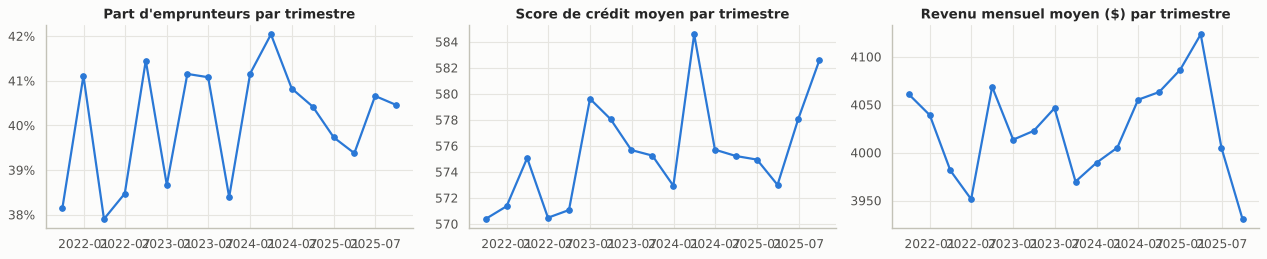

In [12]:
# évolution par trimestre
m = df.set_index("record_date").resample("QE").agg(
    n=("user_id", "size"), taux_emprunteurs=("has_loan", "mean"),
    score_moyen=("credit_score", "mean"), revenu_moyen=("monthly_income_usd", "mean"))
m = m[m.n > 300]   # on retire les trimestres partiels (bords de période)
fig, axes = plt.subplots(1, 3, figsize=(16, 3.4))
for ax, (c, t) in zip(axes, [("taux_emprunteurs", "Part d'emprunteurs"), ("score_moyen", "Score de crédit moyen"),
                              ("revenu_moyen", "Revenu mensuel moyen ($)")]):
    ax.plot(m.index, m[c], marker="o", markersize=5, color=PALETTE[0]); ax.set_title(t + " par trimestre")
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

Pas de tendance dans le temps. Chaque `user_id` n'apparaît qu'une fois, donc pas de risque d'avoir le même client dans le train et le test. Je garde quand même un split temporel, c'est ce qu'on ferait sur des données réelles.

## 5. Feature engineering

Des variables connues au moment d'une demande de prêt, et quelques indicateurs de santé financière pour la partie épargne (reste à vivre, taux d'épargne, nombre de mois de dépenses couverts par l'épargne).

In [13]:
df["expense_ratio"]       = df.monthly_expenses_usd / df.monthly_income_usd
df["disposable_income"]   = df.monthly_income_usd - df.monthly_expenses_usd            # avant crédit
df["net_cashflow"]        = df.disposable_income - df.monthly_emi_usd                  # après crédit
df["net_savings_rate"]    = df.net_cashflow / df.monthly_income_usd
df["emergency_months"]    = df.savings_usd / (df.monthly_expenses_usd + df.monthly_emi_usd)  # mois de « coussin »
df["log_income"]          = np.log(df.monthly_income_usd)
df["log_savings"]         = np.log(df.savings_usd)
df["age_band"]            = pd.cut(df.age, [17, 25, 35, 45, 55, 70], labels=["18-25", "26-35", "36-45", "46-55", "56-69"])
df["year"]                = df.record_date.dt.year
df["credit_band"]         = pd.cut(df.credit_score, [299, 579, 669, 739, 799, 850],
                                   labels=["Poor", "Fair", "Good", "Very good", "Exceptional"])   # tranches FICO

df[["expense_ratio", "disposable_income", "net_cashflow", "net_savings_rate", "emergency_months"]].describe().T

,count,mean,std,min,25%,50%,75%,max
expense_ratio,"32,424.000",0.600,0.173,0.300,0.450,0.601,0.750,0.900
disposable_income,"32,424.000","1,608.418","1,090.053",50.560,752.550,"1,385.815","2,260.682","7,158.310"
net_cashflow,"32,424.000","-1,484.574","6,571.508","-46,671.120","-2,009.057",720.750,"1,728.393","7,097.560"
net_savings_rate,"32,424.000",-0.795,3.765,-90.295,-0.523,0.230,0.458,0.700
emergency_months,"32,424.000",81.121,72.041,0.066,22.844,60.799,122.475,395.410


## 6. Split temporel

- Train : avant le 1er juillet 2024 (environ 3 ans)
- Test : du 1er juillet 2024 au 22 juillet 2025

Variables utilisées dans les modèles (toutes connues avant une décision de crédit) :

In [14]:
CUTOFF = pd.Timestamp("2024-07-01")
train, test = df[df.record_date < CUTOFF].copy(), df[df.record_date >= CUTOFF].copy()
print(f"Train : {len(train):,} lignes ({train.record_date.min():%Y-%m-%d} → {train.record_date.max():%Y-%m-%d})")
print(f"Test  : {len(test):,} lignes ({test.record_date.min():%Y-%m-%d} → {test.record_date.max():%Y-%m-%d})")

NUM_EXANTE = ["age", "log_income", "expense_ratio", "log_savings", "savings_to_income_ratio", "disposable_income"]
CAT_EXANTE = ["gender", "education_level", "employment_status", "region"]

def make_pre(num, cat):
    return ColumnTransformer([("num", StandardScaler(), num),
                              ("cat", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), cat)])

Train : 23,834 lignes (2021-07-23 → 2024-06-30)
Test  : 8,590 lignes (2024-07-01 → 2025-07-22)


## 7. Modèles

### 7.1 Score de crédit

Deux versions : régression sur le score, et classification score ≥ 670 (seuil « Good » de FICO). Chaque modèle est comparé à une baseline (moyenne ou classe majoritaire).

In [15]:
Xtr, Xte = train[NUM_EXANTE + CAT_EXANTE], test[NUM_EXANTE + CAT_EXANTE]
ytr, yte = train.credit_score, test.credit_score

reg_models = {
    "Baseline (moyenne)": DummyRegressor(),
    "Ridge": Pipeline([("pre", make_pre(NUM_EXANTE, CAT_EXANTE)), ("m", Ridge(alpha=1.0))]),
    "Gradient Boosting": Pipeline([("pre", make_pre(NUM_EXANTE, CAT_EXANTE)),
                                   ("m", HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05,
                                                                       random_state=RANDOM_STATE))]),
}
res_reg = []
for name, mdl in reg_models.items():
    mdl.fit(Xtr, ytr); p = mdl.predict(Xte)
    res_reg.append({"modèle": name, "MAE": mean_absolute_error(yte, p), "R²": r2_score(yte, p)})
res_reg = pd.DataFrame(res_reg).set_index("modèle"); res_reg

,MAE,R²
modèle,,
Baseline (moyenne),137.312,-0.000
Ridge,137.333,-0.000
Gradient Boosting,137.339,-0.001


In [16]:
ytr_c, yte_c = (ytr >= 670).astype(int), (yte >= 670).astype(int)
clf_models = {
    "Baseline": DummyClassifier(strategy="prior"),
    "Régression logistique": Pipeline([("pre", make_pre(NUM_EXANTE, CAT_EXANTE)),
                                       ("m", LogisticRegression(max_iter=1000))]),
    "Gradient Boosting": Pipeline([("pre", make_pre(NUM_EXANTE, CAT_EXANTE)),
                                   ("m", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05,
                                                                        random_state=RANDOM_STATE))]),
}
res_cs = []
for name, mdl in clf_models.items():
    mdl.fit(Xtr, ytr_c); s = mdl.predict_proba(Xte)[:, 1]
    res_cs.append({"modèle": name, "AUC": roc_auc_score(yte_c, s)})
res_cs = pd.DataFrame(res_cs).set_index("modèle")
print(f"Part de « bons dossiers » (≥ 670) : train {ytr_c.mean():.1%} | test {yte_c.mean():.1%}")
res_cs

Part de « bons dossiers » (≥ 670) : train 32.8% | test 33.0%


,AUC
modèle,
Baseline,0.500
Régression logistique,0.502
Gradient Boosting,0.505


Pour vérifier que l'AUC de 0,50 correspond bien à du hasard, je fais un test de permutation : on réentraîne le modèle sur des cibles mélangées et on compare.

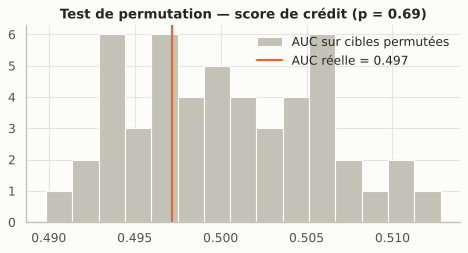

In [17]:
pipe = clf_models["Régression logistique"]
score, perm_scores, pval = permutation_test_score(
    pipe, Xtr, ytr_c, scoring="roc_auc", cv=StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE),
    n_permutations=50, random_state=RANDOM_STATE, n_jobs=-1)
fig, ax = plt.subplots(figsize=(7, 3.2))
ax.hist(perm_scores, bins=15, color="#c3c2b7", edgecolor="#fcfcfb", label="AUC sur cibles permutées")
ax.axvline(score, color=PALETTE[1], lw=2, label=f"AUC réelle = {score:.3f}")
ax.set_title(f"Test de permutation — score de crédit (p = {pval:.2f})"); ax.legend(frameon=False)
plt.show()

R² autour de 0 et AUC autour de 0,50 : aucun modèle ne fait mieux que la baseline, et le test de permutation n'est pas significatif. Le score de crédit est tiré au hasard dans ce dataset, rien ne permet de le prédire.

### 7.2 Éligibilité au prêt (`has_loan`)

D'abord avec les variables connues avant la demande (plus le score de crédit). Ensuite, pour montrer ce que donne une fuite de données, j'ajoute le taux d'intérêt, qui n'existe que si le prêt a été accordé.

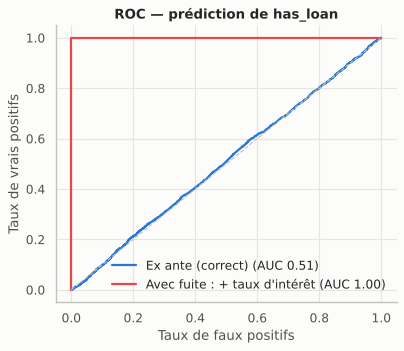

,AUC test
jeu de variables,
Ex ante (correct),0.505
Avec fuite : + taux d'intérêt,1.000


In [18]:
num_loan = NUM_EXANTE + ["credit_score"]
loan_sets = {
    "Ex ante (correct)": (num_loan, CAT_EXANTE),
    "Avec fuite : + taux d'intérêt": (num_loan + ["loan_interest_rate_pct"], CAT_EXANTE),
}
res_loan, rocs = [], {}
for name, (nc, cc) in loan_sets.items():
    mdl = Pipeline([("pre", make_pre(nc, cc)),
                    ("m", HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=RANDOM_STATE))])
    mdl.fit(train[nc + cc], train.has_loan); s = mdl.predict_proba(test[nc + cc])[:, 1]
    res_loan.append({"jeu de variables": name, "AUC test": roc_auc_score(test.has_loan, s)})
    rocs[name] = roc_curve(test.has_loan, s)
res_loan = pd.DataFrame(res_loan).set_index("jeu de variables")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
for (name, (fpr, tpr, _)), col in zip(rocs.items(), [PALETTE[0], PALETTE[7]]):
    ax.plot(fpr, tpr, color=col, label=f"{name} (AUC {res_loan.loc[name, 'AUC test']:.2f})")
ax.plot([0, 1], [0, 1], ls="--", color="#c3c2b7", lw=1)
ax.set_xlabel("Taux de faux positifs"); ax.set_ylabel("Taux de vrais positifs")
ax.set_title("ROC — prédiction de has_loan"); ax.legend(frameon=False, loc="lower right")
plt.show()
res_loan

- Sans fuite : AUC de 0,50, avoir un prêt ne dépend pas du profil (environ 40 % d'emprunteurs partout).
- Avec le taux d'intérêt : AUC de 1,00. Le taux vaut 0 pour tous les non-emprunteurs, donc il donne directement la réponse. Ce modèle serait inutilisable en pratique.

`has_loan` n'est donc pas une vraie décision d'octroi. À la place, je construis une grille d'éligibilité avec des règles.

## 8. Éligibilité avec des règles

Critères inspirés de ce que font les banques :

| Critère | Seuil | Remarque |
|---|---|---|
| Score de crédit | ≥ 620 | minimum courant pour un prêt classique |
| DTI | ≤ 0,43 | plafond utilisé aux États-Unis (en France : taux d'effort ≤ 35 %) |
| Reste à vivre | > 0 | revenu - dépenses - mensualité |

Je l'applique aux prêts existants, puis je calcule pour tout le monde une capacité d'emprunt (mensualité max acceptable).

In [19]:
DTI_MAX, SCORE_MIN = 0.43, 620
borrowers = df[df.has_loan == 1].copy()
borrowers["ok_score"] = borrowers.credit_score >= SCORE_MIN
borrowers["ok_dti"] = borrowers.debt_to_income_ratio <= DTI_MAX
borrowers["ok_cash"] = borrowers.net_cashflow > 0
borrowers["eligible"] = borrowers[["ok_score", "ok_dti", "ok_cash"]].all(axis=1)
print("Prêts existants conformes à chaque critère :")
print(borrowers[["ok_score", "ok_dti", "ok_cash", "eligible"]].mean().map("{:.1%}".format))
print(f"\nDTI médian des emprunteurs : {borrowers.debt_to_income_ratio.median():.2f} "
      f"(la mensualité médiane représente {borrowers.debt_to_income_ratio.median():.0%} du revenu)")

# Capacité d'emprunt de chacun (taux 5 %, 20 ans), plafonnée par le DTI et par le reste à vivre
rate, term = 0.05 / 12, 240
annuity_factor = (1 - (1 + rate) ** -term) / rate
df["max_emi"] = np.minimum(DTI_MAX * df.monthly_income_usd, df.disposable_income).clip(lower=0)
df["max_loan_20y_5pct"] = df.max_emi * annuity_factor
df["eligible_new_loan"] = (df.credit_score >= SCORE_MIN) & (df.has_loan == 0)
print(f"\nNon-emprunteurs éligibles (score ≥ {SCORE_MIN}) : {df.loc[df.has_loan == 0, 'eligible_new_loan'].mean():.1%}")
print(f"Capacité d'emprunt médiane (20 ans, 5 %) : {df.max_loan_20y_5pct.median():,.0f} $")

Prêts existants conformes à chaque critère :
ok_score    42.5%
ok_dti      19.0%
ok_cash     17.5%
eligible     6.6%
dtype: str

DTI médian des emprunteurs : 1.35 (la mensualité médiane représente 135% du revenu)

Non-emprunteurs éligibles (score ≥ 620) : 41.7%
Capacité d'emprunt médiane (20 ans, 5 %) : 190,598 $


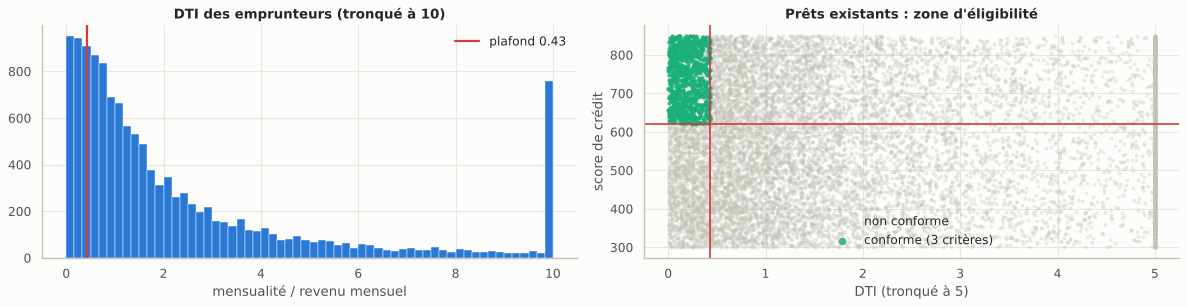

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4))
dti_clip = borrowers.debt_to_income_ratio.clip(upper=10)
axes[0].hist(dti_clip, bins=60, color=PALETTE[0], edgecolor="#fcfcfb", linewidth=0.4)
axes[0].axvline(DTI_MAX, color=STATUS["critical"], lw=2, label=f"plafond {DTI_MAX}")
axes[0].set_title("DTI des emprunteurs (tronqué à 10)"); axes[0].set_xlabel("mensualité / revenu mensuel")
axes[0].legend(frameon=False)

ok = borrowers.eligible
axes[1].scatter(borrowers.loc[~ok, "debt_to_income_ratio"].clip(upper=5), borrowers.loc[~ok, "credit_score"],
                s=6, alpha=0.25, color="#c3c2b7", label="non conforme")
axes[1].scatter(borrowers.loc[ok, "debt_to_income_ratio"], borrowers.loc[ok, "credit_score"],
                s=8, alpha=0.8, color=PALETTE[2], label="conforme (3 critères)")
axes[1].axvline(DTI_MAX, color=STATUS["critical"], lw=1.5); axes[1].axhline(SCORE_MIN, color=STATUS["critical"], lw=1.5)
axes[1].set_xlabel("DTI (tronqué à 5)"); axes[1].set_ylabel("score de crédit")
axes[1].set_title("Prêts existants : zone d'éligibilité"); axes[1].legend(frameon=False, markerscale=2)
plt.tight_layout(); plt.show()

Très peu de prêts existants passeraient ces critères. Les montants (jusqu'à 500 k$) ont été générés sans tenir compte du revenu (environ 4 k$/mois), donc les mensualités dépassent souvent le revenu. C'est une vraie limite du dataset pour la partie éligibilité.

## 9. Dépenses et épargne

Deux règles simples :
1. règle 50/30/20 : épargner au moins 20 % du revenu,
2. épargne de précaution : au moins 6 mois de charges (dépenses + mensualités).

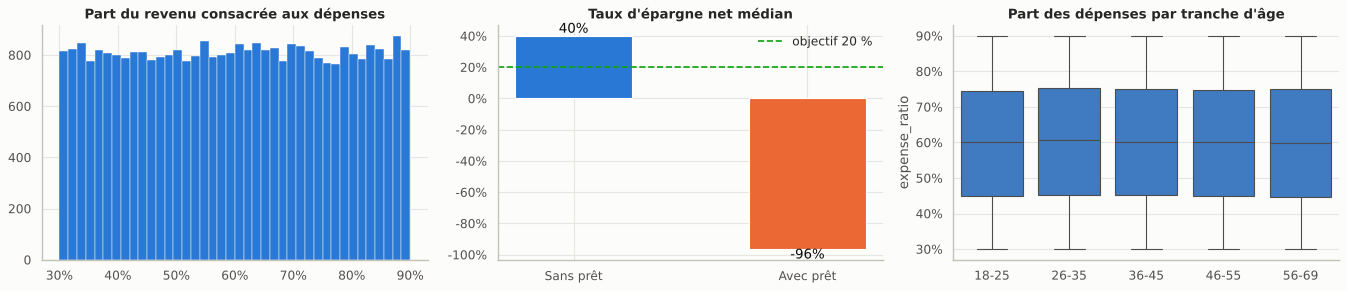

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 3.8))
axes[0].hist(df.expense_ratio, bins=40, color=PALETTE[0], edgecolor="#fcfcfb", linewidth=0.4)
axes[0].set_title("Part du revenu consacrée aux dépenses")
axes[0].xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))

sr = df.groupby("has_loan").net_savings_rate.median()
axes[1].bar(["Sans prêt", "Avec prêt"], sr.values, color=[PALETTE[0], PALETTE[1]], width=0.5)
axes[1].axhline(0.20, color=STATUS["good"], ls="--", lw=1.5, label="objectif 20 %")
axes[1].set_title("Taux d'épargne net médian"); axes[1].legend(frameon=False)
axes[1].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
for i, v in enumerate(sr.values):
    axes[1].text(i, v + (0.02 if v >= 0 else -0.06), f"{v:.0%}", ha="center", color="#0b0b0b")

sns.boxplot(data=df, x="age_band", y="expense_ratio", ax=axes[2], color=PALETTE[0], fliersize=0)
axes[2].set_title("Part des dépenses par tranche d'âge"); axes[2].set_xlabel("")
axes[2].yaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
plt.tight_layout(); plt.show()

In [22]:
def recommend(row):
    if row.net_cashflow < 0:
        return "1. Déficit : restructurer la dette"
    if row.emergency_months < 6:
        return "2. Constituer le fonds d'urgence"
    if row.net_savings_rate < 0.20:
        return "3. Réduire les dépenses (objectif 20 %)"
    return "4. Investir l'excédent"

df["recommendation"] = df.apply(recommend, axis=1)
# Montant de dépenses à réduire pour atteindre 20 % d'épargne nette (si positif et atteignable)
df["expense_cut_needed"] = (0.20 * df.monthly_income_usd - df.net_cashflow).clip(lower=0)
df.loc[df.recommendation.str.startswith("1"), "expense_cut_needed"] = np.nan

reco = (df.groupby("recommendation")
          .agg(effectif=("user_id", "size"), revenu_median=("monthly_income_usd", "median"),
               taux_epargne_median=("net_savings_rate", "median"),
               reduction_depenses_mediane=("expense_cut_needed", "median"))
          .assign(part=lambda d: d.effectif / d.effectif.sum()))
reco

,effectif,revenu_median,taux_epargne_median,reduction_depenses_mediane,part
recommendation,,,,,
1. Déficit : restructurer la dette,10724,"3,811.230",-1.362,NaN,0.331
2. Constituer le fonds d'urgence,488,"4,270.345",0.283,0.000,0.015
3. Réduire les dépenses (objectif 20 %),4269,"4,264.210",0.142,210.156,0.132
4. Investir l'excédent,16943,"4,048.560",0.446,0.000,0.523


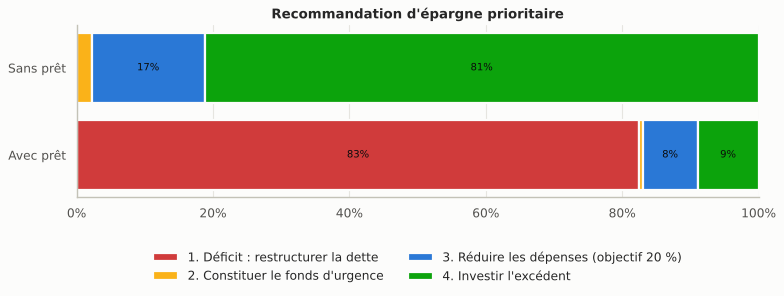

In [23]:
seg = pd.crosstab(df.has_loan.map({0: "Sans prêt", 1: "Avec prêt"}), df.recommendation, normalize="index")
colors = [STATUS["critical"], STATUS["warning"], PALETTE[0], STATUS["good"]]
fig, ax = plt.subplots(figsize=(11, 2.8))
left = np.zeros(len(seg))
for c, col in zip(seg.columns, colors):
    ax.barh(seg.index, seg[c], left=left, color=col, edgecolor="#fcfcfb", linewidth=2, label=c)
    for i, v in enumerate(seg[c]):
        if v > 0.06: ax.text(left[i] + v / 2, i, f"{v:.0%}", ha="center", va="center", color="#0b0b0b", fontsize=9)
    left += seg[c].values
ax.set_xlim(0, 1); ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_title("Recommandation d'épargne prioritaire"); ax.legend(frameon=False, ncol=2, bbox_to_anchor=(0.5, -0.25), loc="upper center")
plt.show()

Sans prêt, le taux d'épargne est élevé (les dépenses font 30 à 90 % du revenu) et l'épargne couvre presque toujours 6 mois : la plupart peuvent investir leur surplus. Avec un prêt, la mensualité met une grosse majorité des gens en déficit, ce qui rejoint les DTI irréalistes vus en partie 8.

## 10. Segmentation des emprunteurs (K-Means)

Variables standardisées : log(1+DTI), part des dépenses, log(épargne/revenu), log(revenu). Je choisis k avec la méthode du coude et le score de silhouette (calculé sur 5 000 points).

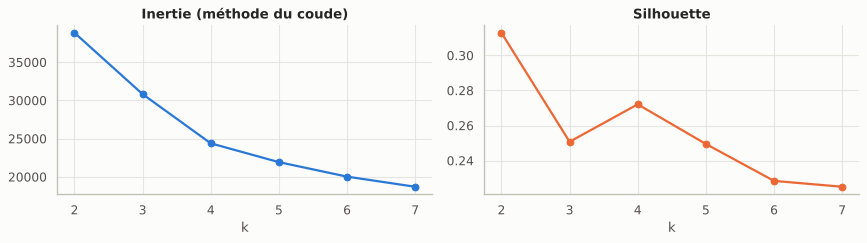

In [24]:
B = df[df.has_loan == 1].copy()
B["log_dti"] = np.log1p(B.debt_to_income_ratio)
B["log_sti"] = np.log(B.savings_to_income_ratio)
clu_cols = ["log_dti", "expense_ratio", "log_sti", "log_income"]
Z = StandardScaler().fit_transform(B[clu_cols])
rng = np.random.default_rng(RANDOM_STATE); idx = rng.choice(len(Z), 5000, replace=False)

ks, sils, inertias = range(2, 8), [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=RANDOM_STATE).fit(Z)
    sils.append(silhouette_score(Z[idx], km.labels_[idx])); inertias.append(km.inertia_)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.2))
axes[0].plot(list(ks), inertias, marker="o", color=PALETTE[0]); axes[0].set_title("Inertie (méthode du coude)")
axes[1].plot(list(ks), sils, marker="o", color=PALETTE[1]); axes[1].set_title("Silhouette")
for a in axes: a.set_xlabel("k")
plt.tight_layout(); plt.show()

In [25]:
K = 4   # k=4 : silhouette correcte et groupes faciles à interpréter
km = KMeans(K, n_init=10, random_state=RANDOM_STATE).fit(Z)
B["cluster"] = km.labels_
# renumérotation des clusters par DTI médian croissant
order = B.groupby("cluster").debt_to_income_ratio.median().sort_values().index
B["cluster"] = B.cluster.map({c: i for i, c in enumerate(order)})
prof = B.groupby("cluster").agg(
    effectif=("user_id", "size"), DTI_median=("debt_to_income_ratio", "median"),
    revenu_median=("monthly_income_usd", "median"), depenses_pct=("expense_ratio", "median"),
    epargne_sur_revenu_annuel=("savings_to_income_ratio", "median"),
    mois_de_coussin=("emergency_months", "median"), en_deficit=("net_cashflow", lambda s: (s < 0).mean()),
    pret_median=("loan_amount_usd", "median"))
sil_k = silhouette_score(Z[idx], B.cluster.values[idx])
print(f"Silhouette (k={K}) : {sil_k:.3f}")
prof

Silhouette (k=4) : 0.272


,effectif,DTI_median,revenu_median,depenses_pct,epargne_sur_revenu_annuel,mois_de_coussin,en_deficit,pret_median
cluster,,,,,,,,
0,4397,1.070,"4,424.530",0.435,5.950,42.085,0.709,"233,368.420"
1,4768,1.090,"4,371.395",0.752,5.940,34.237,0.868,"236,290.090"
2,1978,1.230,"4,182.975",0.603,0.930,5.240,0.823,"249,813.895"
3,1852,7.995,"1,171.825",0.591,5.070,6.629,0.993,"322,350.095"


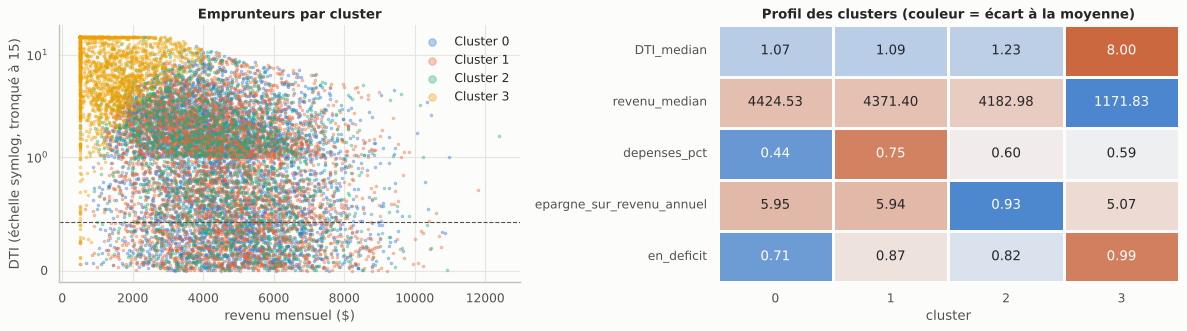

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
for c in range(K):
    s = B[B.cluster == c]
    axes[0].scatter(s.monthly_income_usd, s.debt_to_income_ratio.clip(upper=15), s=5, alpha=0.35,
                    color=PALETTE[c], label=f"Cluster {c}")
axes[0].set_yscale("symlog", linthresh=1); axes[0].axhline(DTI_MAX, color="#52514e", ls="--", lw=1)
axes[0].set_xlabel("revenu mensuel ($)"); axes[0].set_ylabel("DTI (échelle symlog, tronqué à 15)")
axes[0].set_title("Emprunteurs par cluster"); axes[0].legend(frameon=False, markerscale=3)

prof_z = (prof[["DTI_median", "revenu_median", "depenses_pct", "epargne_sur_revenu_annuel", "en_deficit"]]
          .apply(lambda s: (s - s.mean()) / s.std()))
sns.heatmap(prof_z.T, cmap=sns.diverging_palette(250, 25, s=75, l=55, as_cmap=True), center=0, annot=prof[prof_z.columns].T,
            fmt=".2f", ax=axes[1], cbar=False, linewidths=1, linecolor="#fcfcfb")
axes[1].set_title("Profil des clusters (couleur = écart à la moyenne)")
plt.tight_layout(); plt.show()

Les 4 groupes (triés par DTI médian) :
- 0 : endettés mais dépensent peu (44 % du revenu), beaucoup d'épargne, le moins de déficits
- 1 : même DTI mais dépenses à 75 % du revenu, presque 9 sur 10 en déficit
- 2 : peu d'épargne (moins d'un an de revenu, environ 5 mois de charges)
- 3 : revenus faibles (~1 200 $/mois) et DTI médian de 8, quasiment tous en déficit

La silhouette reste moyenne (0,27). Vu que les variables sont générées indépendamment, il n'y a pas vraiment de groupes naturels : K-Means coupe un nuage de points continu. Ça reste utile comme classement par niveau de risque.

## 11. Dashboard

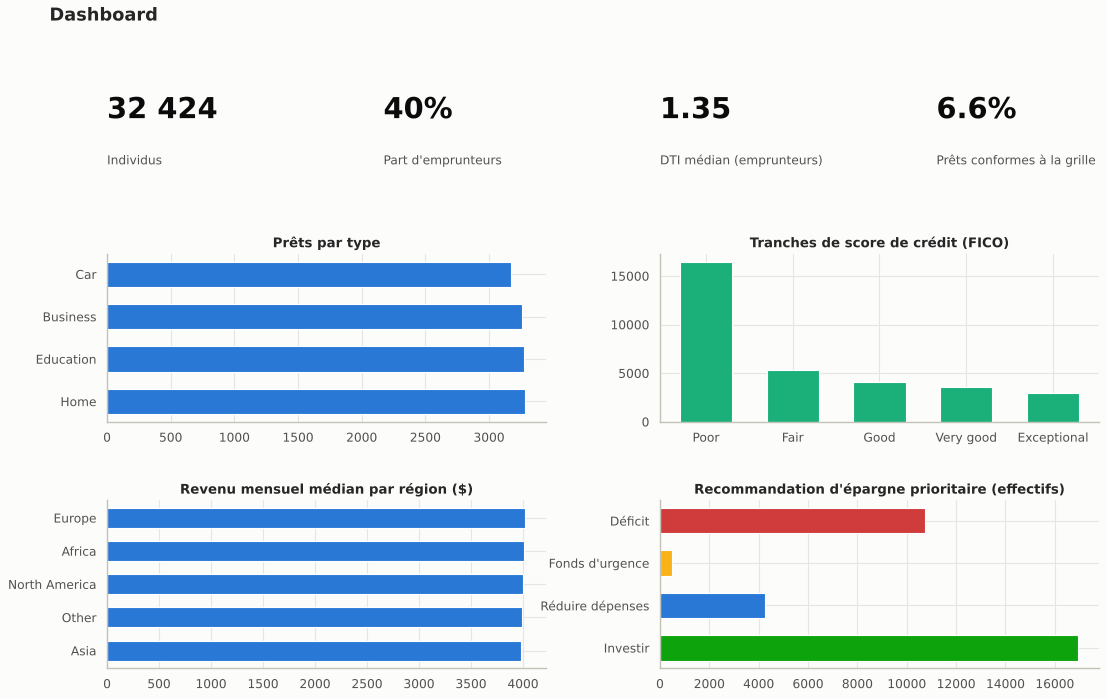

In [27]:
fig = plt.figure(figsize=(16, 9.5))
gs = fig.add_gridspec(3, 4, height_ratios=[0.55, 1, 1], hspace=0.55, wspace=0.7)
kpis = [("Individus", f"{len(df):,}".replace(",", " ")), ("Part d'emprunteurs", f"{df.has_loan.mean():.0%}"),
        ("DTI médian (emprunteurs)", f"{borrowers.debt_to_income_ratio.median():.2f}"),
        ("Prêts conformes à la grille", f"{borrowers.eligible.mean():.1%}")]
for i, (lab, val) in enumerate(kpis):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.text(0, 0.62, val, fontsize=26, fontweight="bold", color="#0b0b0b", transform=ax.transAxes)
    ax.text(0, 0.12, lab, fontsize=11, color="#52514e", transform=ax.transAxes)

ax = fig.add_subplot(gs[1, :2])
lt = df[df.has_loan == 1].loan_type.value_counts()
ax.barh(lt.index, lt.values, color=PALETTE[0], height=0.6); ax.set_title("Prêts par type")
ax2 = fig.add_subplot(gs[1, 2:])
cb = df.credit_band.value_counts().reindex(["Poor", "Fair", "Good", "Very good", "Exceptional"])
ax2.bar(cb.index, cb.values, color=PALETTE[2], width=0.6); ax2.set_title("Tranches de score de crédit (FICO)")
ax3 = fig.add_subplot(gs[2, :2])
inc = df.groupby("region").monthly_income_usd.median().sort_values()
ax3.barh(inc.index, inc.values, color=PALETTE[0], height=0.6); ax3.set_title("Revenu mensuel médian par région ($)")
ax4 = fig.add_subplot(gs[2, 2:])
rc = df.recommendation.value_counts().sort_index()
short = ["Déficit", "Fonds d'urgence", "Réduire dépenses", "Investir"]
ax4.barh(short[::-1], rc.values[::-1], color=colors[::-1], height=0.6)
ax4.set_title("Recommandation d'épargne prioritaire (effectifs)")
fig.suptitle("Dashboard", fontsize=16, fontweight="bold", x=0.08, ha="left")
plt.show()

## 12. Métriques

In [28]:
metrics = {
    "credit_score_R2_GB": round(res_reg.loc["Gradient Boosting", "R²"], 4),
    "credit_score_MAE_GB": round(res_reg.loc["Gradient Boosting", "MAE"], 1),
    "credit_score_MAE_baseline": round(res_reg.loc["Baseline (moyenne)", "MAE"], 1),
    "good_credit_AUC_logit": round(res_cs.loc["Régression logistique", "AUC"], 4),
    "permutation_pvalue": round(pval, 3),
    "has_loan_AUC_exante": round(res_loan.loc["Ex ante (correct)", "AUC test"], 4),
    "has_loan_AUC_avec_fuite": round(res_loan.loc["Avec fuite : + taux d'intérêt", "AUC test"], 4),
    "prets_conformes_pct": round(100 * borrowers.eligible.mean(), 2),
    "DTI_median_emprunteurs": round(borrowers.debt_to_income_ratio.median(), 2),
    "silhouette_kmeans_k4": round(sil_k, 3),
}
pd.Series(metrics)

credit_score_R2_GB           -0.001
credit_score_MAE_GB         137.300
credit_score_MAE_baseline   137.300
good_credit_AUC_logit         0.502
permutation_pvalue            0.686
has_loan_AUC_exante           0.505
has_loan_AUC_avec_fuite       1.000
prets_conformes_pct           6.580
DTI_median_emprunteurs        1.350
silhouette_kmeans_k4          0.272
dtype: float64

## 13. Conclusion

- Données propres : pas de vrais manquants ni de doublons. `job_title` n'est pas cohérent avec `employment_status`.
- Trois colonnes sont calculées (mensualité, DTI, ratio épargne/revenu), le reste est généré indépendamment.
- Le score de crédit ne peut pas être prédit (R² ≈ 0, AUC ≈ 0,5).
- `has_loan` ne correspond pas à une décision d'octroi. Ajouter une variable post-octroi donne une AUC de 1 mais c'est une fuite. La grille de règles est plus utile, et elle montre que presque tous les prêts du dataset seraient refusés.
- Épargne : bonne situation sans crédit, déficit pour la majorité des emprunteurs.
- La segmentation donne une grille de risque lisible, mais pas de vrais groupes.

Ce que je retiens surtout : vérifier les relations entre variables avant de modéliser, toujours comparer à une baseline, et faire attention aux fuites de données.

## 14. Suite

- Simuler un score de crédit qui dépend vraiment du profil pour entraîner un modèle de scoring utile.
- Simuler des décisions d'octroi et regarder l'équité entre groupes et la calibration.
- Tester sur des données réelles (Lending Club, Home Credit).
- Faire une version interactive du dashboard (Streamlit).
- Adapter les seuils au cas français (taux d'effort 35 %, 25 ans max).